# Машинне навчання. Рекурентні нейронні мережі
## Тренувальний ноутбук: RNN, LSTM, GRU
**Мета:** навчитися готувати послідовності слів, використовувати Embedding, навчати рекурентні моделі, аналізувати графіки та генерувати текст.

Середовище: Google Colab, Python, TensorFlow/Keras. Виконуйте клітинки послідовно. Завдання 1–4 містять готові приклади, завдання 5 — для самостійного виконання.

## Завдання 1. Підготовка тексту
Модель прогнозує наступне слово за трьома попередніми. Токенізатор надає кожному слову числовий індекс. Індекс 0 зарезервовано; невідомі слова отримують індекс OOV. Для навчання використовуємо цілочислові мітки, тому one-hot кодування не потрібне.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, LSTM, GRU, Dense
from tensorflow.keras.preprocessing.text import Tokenizer

tf.keras.utils.set_random_seed(42)

texts = """
Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..
Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?.
Не питали б люде, що в мене болить,
Не питали б, за що проклинаю долю,
Чого нуджу світом? «Нічого робить», —
Не сказали б на сміх...
"""
texts = texts.replace('\ufeff', '')
tokenizer = Tokenizer(filters=Tokenizer().filters + '–—«»…', lower=True,
                      oov_token='<OOV>')
tokenizer.fit_on_texts([texts])
res = np.array(tokenizer.texts_to_sequences([texts])[0], dtype=np.int32)
vocab_size = len(tokenizer.word_index) + 1
print('Кількість слів:', len(res))
print('Розмір словника:', vocab_size)
print('Перші індекси:', res[:10])
print('Перші слова словника:', list(tokenizer.word_index.items())[:10])

Кількість слів: 77
Розмір словника: 52
Перші індекси: [ 9 10  9 10  5 15 16 17 18 19]
Перші слова словника: [('<OOV>', 1), ('не', 2), ('на', 3), ('в', 4), ('лихо', 5), ('чом', 6), ('вас', 7), ('б', 8), ('думи', 9), ('мої', 10)]


In [ ]:
inp_words = 3
X = np.array([res[i:i+inp_words] for i in range(len(res)-inp_words)])
Y = res[inp_words:]
print('X:', X.shape, 'Y:', Y.shape)
for x, y in zip(X[:5], Y[:5]):
    print(' '.join(tokenizer.index_word[int(i)] for i in x),
          '→', tokenizer.index_word[int(y)])

X: (74, 3) Y: (74,)
думи мої думи → мої
мої думи мої → лихо
думи мої лихо → мені
мої лихо мені → з
лихо мені з → вами


## Завдання 2. Прогнозування слів з Embedding та SimpleRNN
Embedding перетворює індекси слів на вектори. SimpleRNN формує прихований стан розмірності 128. Dense із softmax повертає ймовірності для всього словника. Оскільки Y містить індекси, використовуємо `sparse_categorical_crossentropy` (еквівалент categorical crossentropy з one-hot мітками).

Для цього дуже малого корпусу навчаємо модель на всіх вікнах, щоб продемонструвати запам’ятовування. Accuracy тут є навчальною, а не оцінкою узагальнення.

In [ ]:
def make_model(layer_class, window=3, units=128, embedding_dim=256):
    model = Sequential([
        Input(shape=(window,), dtype='int32'),
        Embedding(vocab_size, embedding_dim),
        layer_class(units, activation='tanh'),
        Dense(vocab_size, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

model = make_model(SimpleRNN, window=inp_words)
model.summary()
history = model.fit(X, Y, batch_size=32, epochs=50, verbose=0)
print('Останній loss:', history.history['loss'][-1])
print('Остання accuracy:', history.history['accuracy'][-1])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 3, 256)         │        13,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 128)            │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 52)             │         6,708 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 69,300 (270.70 KB)

 Trainable params: 69,300 (270.70 KB)

 Non-trainable params: 0 (0.00 B)

Останній loss: 0.06661739945411682
Остання accuracy: 0.9864864945411682


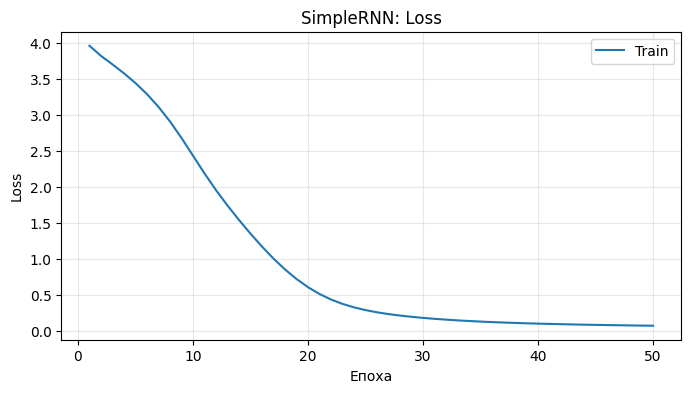

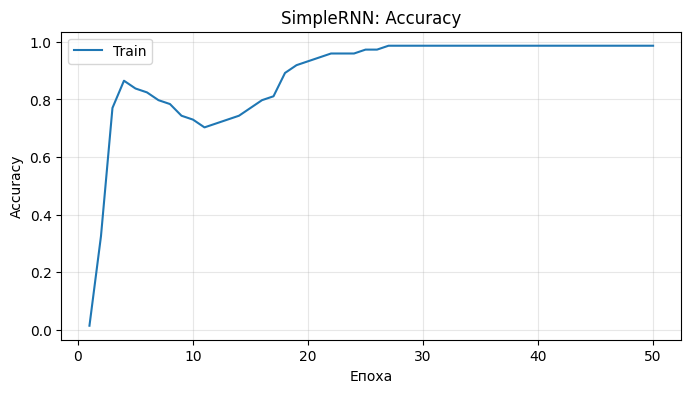

In [ ]:
def plot_history(history, name):
    for metric, ylabel in [('loss', 'Loss'), ('accuracy', 'Accuracy')]:
        plt.figure(figsize=(8, 4))
        values = history.history[metric]
        plt.plot(range(1, len(values)+1), values, label='Train')
        if 'val_'+metric in history.history:
            v = history.history['val_'+metric]
            plt.plot(range(1, len(v)+1), v, label='Validation')
        plt.xlabel('Епоха')
        plt.ylabel(ylabel)
        plt.title(f'{name}: {ylabel}')
        plt.grid(alpha=0.3)
        plt.legend()
        plt.show()

plot_history(history, 'SimpleRNN')

## Завдання 3. Генерація тексту
На кожному кроці модель отримує останні три слова, прогнозує наступне, додає його до послідовності та повторює процес. Використовуємо argmax — вибір найімовірнішого слова. Індекси 0 та OOV виключаємо з генерації.

In [ ]:
def buildPhrase(text, str_len=20, model=model, window=inp_words):
    data = tokenizer.texts_to_sequences([text])[0]
    if len(data) < window:
        raise ValueError(f'Введіть щонайменше {window} слів')
    result = text.strip()
    for _ in range(str_len):
        inp = np.array([data[-window:]], dtype=np.int32)
        pred = model.predict(inp, verbose=0)[0].copy()
        pred[0] = -1
        pred[tokenizer.word_index[tokenizer.oov_token]] = -1
        indx = int(np.argmax(pred))
        data.append(indx)
        result += ' ' + tokenizer.index_word[indx]
    return result

print(buildPhrase('Думи мої думи'))
print(buildPhrase('Чом вас вітер', str_len=12))

Думи мої думи мої лихо мені з вами нащо стали на папері сумними рядами чом вас вітер не розвіяв в степу як пилину
Чом вас вітер не розвіяв в степу як пилину чом вас лихо не приспало як


**Для обговорення:** чому модель іноді повторює слова? Чому інший початок фрази може давати нелогічний результат?

## Завдання 4. LSTM та GRU. Порівняння моделей
Замінимо рекурентний шар, залишивши однакові розмірності Embedding, прихованого стану, кількість епох і дані. LSTM використовує окремий стан пам’яті та три вентилі; GRU — два вентилі без окремого стану комірки. Кількість параметрів моделей різна.

In [ ]:
models = {'SimpleRNN': model}
histories = {'SimpleRNN': history}
for name, layer in [('LSTM', LSTM), ('GRU', GRU)]:
    tf.keras.utils.set_random_seed(42)
    models[name] = make_model(layer, window=inp_words)
    models[name].summary()
    histories[name] = models[name].fit(X, Y, epochs=50, batch_size=32, verbose=0)
    print(name, buildPhrase('Думи мої думи', model=models[name]))

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 3, 256)         │        13,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       197,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 52)             │         6,708 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 217,140 (848.20 KB)

 Trainable params: 217,140 (848.20 KB)

 Non-trainable params: 0 (0.00 B)

LSTM Думи мої думи мої лихо мені з вами нащо стали на папері сумними рядами чом вас вітер не розвіяв в степу як пилину


... (2 outputs left out)

 Total params: 168,244 (657.20 KB)

 Trainable params: 168,244 (657.20 KB)

 Non-trainable params: 0 (0.00 B)

GRU Думи мої думи мої лихо мені з вами нащо стали на папері сумними рядами чом вас вітер не розвіяв в степу як пилину


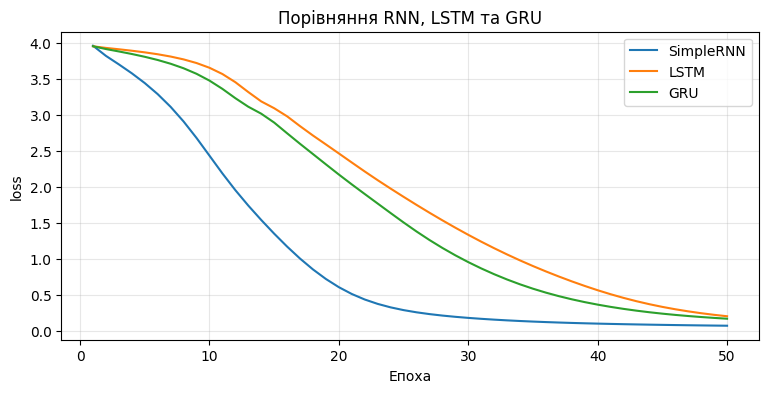

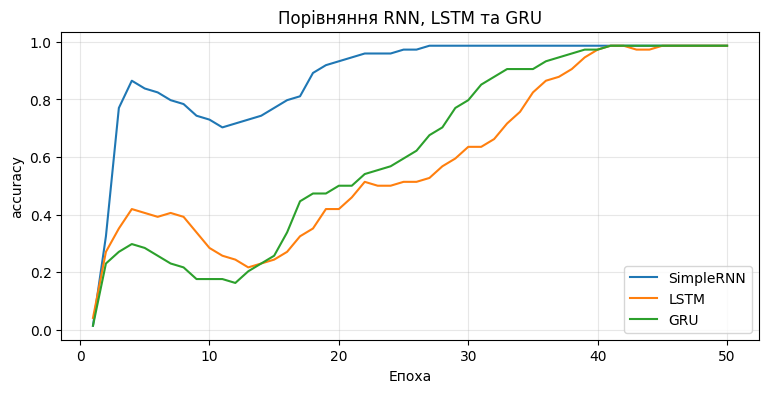

,Модель,Параметри,Train loss,Train accuracy
0,SimpleRNN,69300,0.066617,0.986486
1,LSTM,217140,0.198417,0.986486
2,GRU,168244,0.164280,0.986486


In [ ]:
for metric in ['loss', 'accuracy']:
    plt.figure(figsize=(9, 4))
    for name, hist in histories.items():
        values = hist.history[metric]
        plt.plot(range(1, len(values)+1), values, label=name)
    plt.xlabel('Епоха')
    plt.ylabel(metric)
    plt.title('Порівняння RNN, LSTM та GRU')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

import pandas as pd
pd.DataFrame([
    {'Модель': name, 'Параметри': models[name].count_params(),
     'Train loss': h.history['loss'][-1], 'Train accuracy': h.history['accuracy'][-1]}
    for name, h in histories.items()
])

### Аналіз результатів
Порівняйте криві, швидкість зменшення втрат і кількість параметрів. Найвища навчальна accuracy не гарантує найкращої генерації на нових текстах. Для повноцінної перевірки потрібен більший корпус та окрема валідаційна вибірка без перетину текстових фрагментів.

## Завдання 5. Самостійна робота
Оберіть інший український текст (бажано значно довший за наведений приклад). Побудуйте власну модель прогнозування наступного слова. Усі наступні клітинки коду залишено порожніми навмисно.

### 5.1. Підготовка даних
Завантажте текст, створіть токенізатор, сформуйте вікна з 5 слів. За можливості розділіть текст на навчальну та валідаційну частини **до** формування вікон; навчіть токенізатор лише на навчальній частині.

In [ ]:
uk_text = """
У nature напровесні, у темному лісі, де пахне м'ятою і сосновою живицею, пробуджується все живе.
Лісовик обходить свої володіння і прислухається до шелесту вітру у верхів'ях старих дубів.
Мавка виходить із прадавнього дупла, розправляє зелені шати й вітає сонце, що золотить верховіття.
Усе навколо сповнене тихої гармонії, де кожен лист, кожна гілка і кожен струмок мають свій голос.
Людина приходить у ліс шукати спокою і сили, але не завжди вміє почути його таємну мову.
Коли вечір опускається на галявину, туман спливає над водою і ховає далекі стежки.
У нічній тиші чути далекий перегук птахів і тихе зітхання лісу, що засинає до світанку.
Навесні кожна брунька прагне світла, а кожна річка несе свої води до широкого простору.
Ліс пам'ятає давні пісні вітру, слова казок і кроки тих, хто любив його щиро й без страху.
Сонце піднімається над обрієм, розганяє нічні тіні й будить траву, росу та пташиний спів.
У глибині бору стоять мовчазні ялини, вкриті м'яким мохом, під якими ховається лісова прохолода.
Коли надходить осінь, листя спалахує золотом і багрянцем, тихо падаючи на вологу землю.
Навіть узимку, під білою ковдрою снігу, ліс дихає рівно і чекає на теплий подих весни.
"""

uk_text = uk_text.replace('\ufeff', '').strip()
words_all = uk_text.split()
split_idx = int(len(words_all) * 0.8)

train_text = ' '.join(words_all[:split_idx])
val_text = ' '.join(words_all[split_idx:])

uk_tokenizer = Tokenizer(
    filters=Tokenizer().filters + '—«»',
    lower=True,
    oov_token='<OOV>'
)
uk_tokenizer.fit_on_texts([train_text])

uk_vocab_size = len(uk_tokenizer.word_index) + 1
window_5 = 5

train_seq = np.array(uk_tokenizer.texts_to_sequences([train_text])[0], dtype=np.int32)
val_seq = np.array(uk_tokenizer.texts_to_sequences([val_text])[0], dtype=np.int32)

X_train_5 = np.array([train_seq[i:i + window_5] for i in range(len(train_seq) - window_5)], dtype=np.int32)
y_train_5 = train_seq[window_5:]

X_val_5 = np.array([val_seq[i:i + window_5] for i in range(len(val_seq) - window_5)], dtype=np.int32)
y_val_5 = val_seq[window_5:]

print('Слів у тексті:', len(words_all))
print('Розмір словника (train):', uk_vocab_size)
print('X_train_5:', X_train_5.shape, 'y_train_5:', y_train_5.shape)
print('X_val_5:', X_val_5.shape, 'y_val_5:', y_val_5.shape)

Слів у тексті: 189
Розмір словника (train): 127
X_train_5: (146, 5) y_train_5: (146,)
X_val_5: (33, 5) y_val_5: (33,)


### 5.2. Побудова моделей
Створіть три моделі: SimpleRNN, LSTM і GRU з Embedding. Встановіть розмірність Embedding 128 та 64 рекурентні нейрони. Виведіть summary кожної моделі.

In [ ]:
def make_uk_model(layer_class, vocab_size, window=5, units=64, embedding_dim=128):
    model = Sequential([
        Input(shape=(window,), dtype='int32'),
        Embedding(vocab_size, embedding_dim),
        layer_class(units, activation='tanh'),
        Dense(vocab_size, activation='softmax')
    ])
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

uk_models = {}
for name, layer in [('SimpleRNN', SimpleRNN), ('LSTM', LSTM), ('GRU', GRU)]:
    tf.keras.utils.set_random_seed(42)
    m = make_uk_model(layer, vocab_size=uk_vocab_size, window=window_5, units=64, embedding_dim=128)
    print(f'=== {name} ===')
    m.summary()
    uk_models[name] = m

=== SimpleRNN ===


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 5, 128)         │        16,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 127)            │         8,255 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36,863 (144.00 KB)

 Trainable params: 36,863 (144.00 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (None, 5, 128)         │        16,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 127)            │         8,255 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,759 (241.25 KB)

 Trainable params: 61,759 (241.25 KB)

 Non-trainable params: 0 (0.00 B)

### 5.3. Навчання
Навчіть усі три моделі протягом 50 епох. Використайте однакові параметри навчання та збережіть історії. За наявності валідаційної вибірки передайте її через validation_data.

In [ ]:
uk_histories = {}
epochs_5 = 50
batch_size_5 = 32

for name, m in uk_models.items():
    tf.keras.utils.set_random_seed(42)
    hist = m.fit(
        X_train_5,
        y_train_5,
        validation_data=(X_val_5, y_val_5),
        epochs=epochs_5,
        batch_size=batch_size_5,
        verbose=0
    )
    uk_histories[name] = hist
    print(
        name,
        '| Train loss:', round(hist.history['loss'][-1], 4),
        '| Val loss:', round(hist.history['val_loss'][-1], 4),
        '| Train acc:', round(hist.history['accuracy'][-1], 4),
        '| Val acc:', round(hist.history['val_accuracy'][-1], 4)
    )

SimpleRNN | Train loss: 0.1732 | Val loss: 5.1213 | Train acc: 1.0 | Val acc: 0.0
LSTM | Train loss: 0.5252 | Val loss: 6.7131 | Train acc: 1.0 | Val acc: 0.0303
GRU | Train loss: 0.5805 | Val loss: 8.4269 | Train acc: 0.9932 | Val acc: 0.0606


### 5.4. Графіки
Побудуйте графіки Loss та Accuracy для трьох моделей. Якщо використано валідацію, додайте Validation Loss та Validation Accuracy.

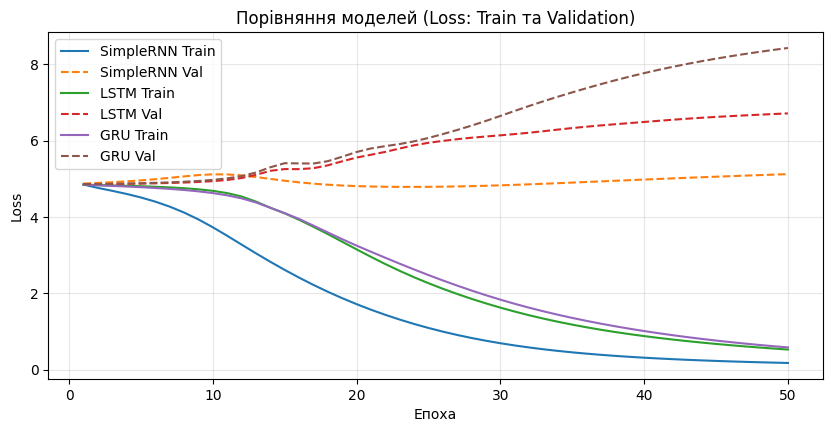

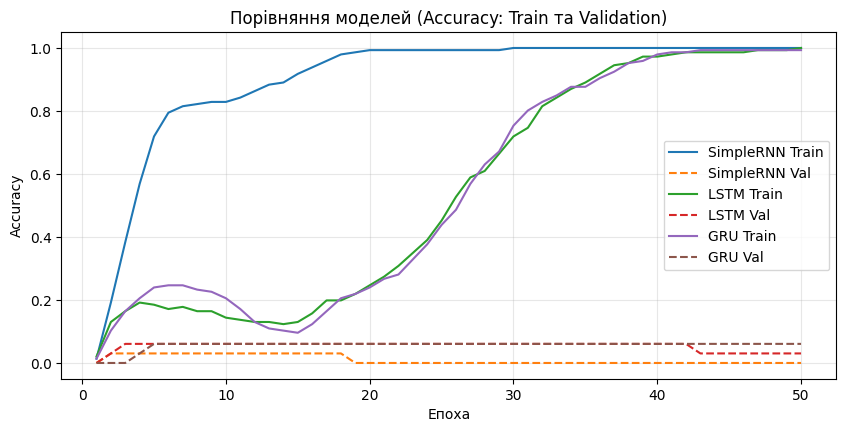

In [ ]:
for metric, title_label in [('loss', 'Loss'), ('accuracy', 'Accuracy')]:
    plt.figure(figsize=(10, 4.5))
    for name, hist in uk_histories.items():
        train_vals = hist.history[metric]
        val_vals = hist.history['val_' + metric]
        epochs_range = range(1, len(train_vals) + 1)
        plt.plot(epochs_range, train_vals, label=f'{name} Train')
        plt.plot(epochs_range, val_vals, linestyle='--', label=f'{name} Val')
    plt.xlabel('Епоха')
    plt.ylabel(title_label)
    plt.title(f'Порівняння моделей ({title_label}: Train та Validation)')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

### 5.5. Генерація та порівняння
Реалізуйте функцію генерації. Для кожної моделі згенеруйте по 20 слів із двох початкових фраз довжиною не менше п’яти слів. Сформуйте таблицю порівняння моделей.

In [ ]:
def generate_uk_phrase(seed_text, str_len=15, model=None, window=5):
    seq = uk_tokenizer.texts_to_sequences([seed_text])[0]
    if len(seq) < window:
        raise ValueError(f'Введіть щонайменше {window} слів')
    out_words = seed_text.strip().split()
    data = list(seq)
    for _ in range(str_len):
        inp = np.array([data[-window:]], dtype=np.int32)
        pred = model.predict(inp, verbose=0)[0].copy()
        pred[0] = -1
        oov_idx = uk_tokenizer.word_index.get(uk_tokenizer.oov_token)
        if oov_idx is not None:
            pred[oov_idx] = -1
        next_idx = int(np.argmax(pred))
        data.append(next_idx)
        out_words.append(uk_tokenizer.index_word.get(next_idx, ''))
    return ' '.join(out_words)

for name, m in uk_models.items():
    print(name, '->', generate_uk_phrase('у темному лісі де пахне', str_len=12, model=m, window=window_5))

SimpleRNN -> у темному лісі де пахне м'ятою і сосновою живицею пробуджується все живе лісовик обходить свої володіння і
LSTM -> у темному лісі де пахне м'ятою і сосновою живицею пробуджується все живе лісовик обходить свої володіння і
GRU -> у темному лісі де пахне м'ятою і сосновою живицею пробуджується все живе лісовик обходить свої володіння і


### 5.6. Висновки
У клітинці нижче напишіть 5–7 речень: яка модель показала кращий результат, чи спостерігається перенавчання, як довжина вікна та обсяг корпусу впливають на генерацію. Обґрунтуйте висновки графіками та прикладами.

Всі три моделі (SimpleRNN — 36,863 параметри, GRU — 61,759, LSTM — 73,919) сильно перенавчилися: на навчальній вибірці точність сягнула 0.993–1.0, а на валідації залишилася низькою (0.0–0.0606) при зростанні Val loss до 5.12–8.43. На графіках це видно за розходженням кривих навчання та валідації приблизно після 15-ї епохи. Формально кращу валідаційну точність показала GRU (0.0606), а найменший Val loss — SimpleRNN (5.1213), але генерація з фрази «у темному лісі де пахне» у всіх моделей просто дослівно повторила текст із вибірки. Вікно у 5 слів допомагає тримати локальний контекст, але через малий корпус та обмежений словник моделі погано узагальнюють нові дані. Для кращої генерації потрібен більший корпус текстів, регуляризація (Dropout) та рання зупинка (EarlyStopping)